# Lab 11 - Attention
### Name: Abdullah Alnaji
### ID: 2240007157
### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

## Step 1 — Import libraries

In [2]:
import re, collections
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Load the dataset

In [3]:
import os
path = "Lab_11_QnA_Dataset.csv"
if not os.path.exists(path):
    path = "/content/Lab_11_QnA_Dataset.csv"   # Google Colab upload location
df = pd.read_csv(path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
df.head()

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing
1. Lowercase + remove punctuation  2. Word → number  3. Padding with zeros.

(Implemented in plain Python so it runs without TensorFlow; it does the same job as Keras `Tokenizer` + `pad_sequences(padding="post")`. Index 0 is reserved for padding.)

In [4]:
df["question"] = df["question"].str.lower()

def tokenize(text):
    return re.sub(r"[^\w\s']", "", text).split()     # remove punctuation, split into words

# word -> number (most frequent word gets 1, like Keras Tokenizer)
counts = collections.Counter(w for q in df["question"] for w in tokenize(q))
word_index = {w: i + 1 for i, (w, _) in enumerate(counts.most_common())}

sequences = [[word_index[w] for w in tokenize(q)] for q in df["question"]]
max_len = max(len(s) for s in sequences)
X = torch.tensor([s + [0] * (max_len - len(s)) for s in sequences], dtype=torch.long)  # post-padding
y = torch.tensor(df["answer_id"].values, dtype=torch.long)

print("Vocabulary size:", len(word_index), "| X shape:", tuple(X.shape))

Vocabulary size: 226 | X shape: (168, 11)


## Step 4 — RNN with attention
Fixes compared with the starter code (so that attention is really computed per question):
- `batch_first=True` → the RNN reads each question word by word (the starter code made it run over the *batch* dimension).
- Padding positions get a very negative score before `softmax`, so they receive **0 attention**.
- `padding_idx=0` in the embedding.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc  = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))                       # (batch, words, 32)
        scores = self.att(h).squeeze(-1)                   # one score per word
        scores = scores.masked_fill(x == 0, -1e9)          # ignore padding
        weights = torch.softmax(scores, dim=1)             # attention weights (sum = 1)
        context = (h * weights.unsqueeze(-1)).sum(1)       # weighted sum of word states
        return self.fc(context), weights

model = RNN()

## Step 5 — Train
(Added `optimizer.zero_grad()` — the starter code forgot it, so gradients piled up.)

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()                                   # clear old gradients
    loss = nn.functional.cross_entropy(model(X)[0], y)      # calculate loss
    loss.backward()                                         # backpropagation
    optimizer.step()                                        # update parameters
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:2d}  loss {loss.item():.4f}")

model.eval()
with torch.no_grad():
    acc = (model(X)[0].argmax(1) == y).float().mean().item()
print("Training finished!  Training accuracy:", round(acc, 3))

epoch 10  loss 1.9305
epoch 20  loss 1.2049
epoch 30  loss 0.5520
epoch 40  loss 0.1980
epoch 50  loss 0.0688
Training finished!  Training accuracy: 0.988


## Step 6 — See attention (helper function)
One function used for the original step and both tasks.

'do you get hurt?'                            -> highest attention: 'get' (0.89)


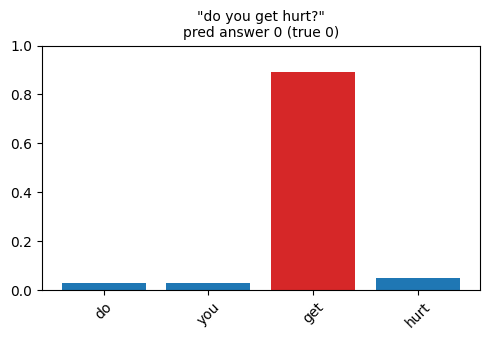

In [7]:
def attention_for(question_idx):
    words = tokenize(df["question"][question_idx])
    with torch.no_grad():
        pred, w = model(X[question_idx:question_idx + 1])
    return words, w[0, :len(words)].tolist(), pred.argmax().item()

def plot_attention(indices):
    fig, axes = plt.subplots(1, len(indices), figsize=(5 * len(indices), 3.5))
    axes = [axes] if len(indices) == 1 else axes
    for ax, i in zip(axes, indices):
        words, weights, pred = attention_for(i)
        top = words[weights.index(max(weights))]
        ax.bar(words, weights, color=["tab:red" if w == top else "tab:blue" for w in words])
        ax.set_title(f'"{df["question"][i]}"\npred answer {pred} (true {df["answer_id"][i]})', fontsize=10)
        ax.set_ylim(0, 1)
        ax.tick_params(axis="x", rotation=45)
        print(f'{df["question"][i]!r:45} -> highest attention: {top!r} ({max(weights):.2f})')
    plt.tight_layout(); plt.show()

plot_attention([0])      # original Step 6 (first question)

## Task 1 — Understand Attention Weights

'who is your designer?'                       -> highest attention: 'designer' (0.99)
'do you eat cake?'                            -> highest attention: 'cake' (0.77)
"what's your age?"                            -> highest attention: 'your' (0.53)


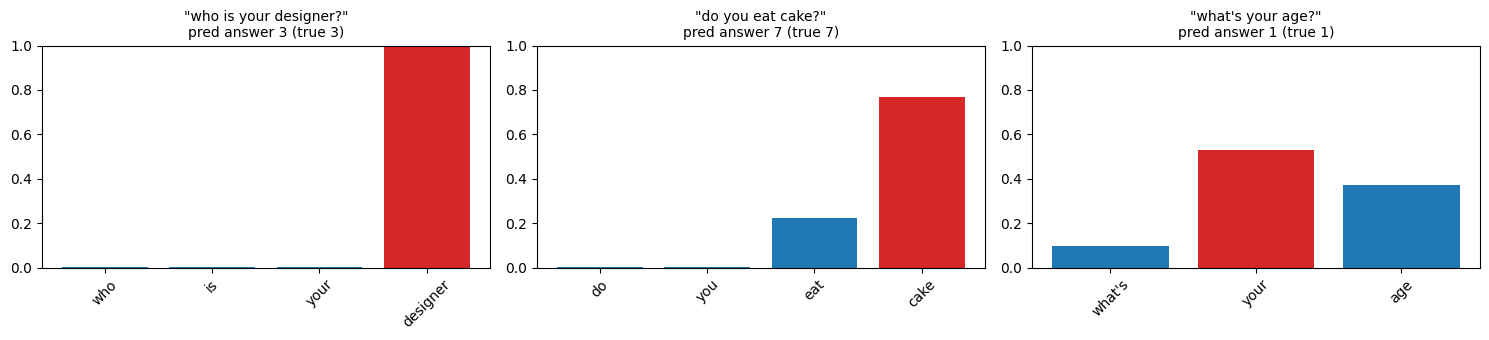

In [8]:
def idx(q): return df.index[df["question"] == q][0]

task1 = [idx("who is your designer?"), idx("do you eat cake?"), idx("what's your age?")]
plot_attention(task1)

### Answer — Task 1
| Question | Highest-attention word | Weight |
|---|---|---|
| who is your designer? | **designer** | 0.99 |
| do you eat cake? | **cake** | 0.77 |
| what's your age? | **your** | 0.53 (`age` gets 0.37) |

**Do the highest-attention words look important?** In most cases, yes. For *"who is your designer?"* and *"do you eat cake?"* the model puts almost all its attention on the content word (`designer`, `cake`) — exactly the word that decides the topic (who made the bot / food), while function words like `who`, `is`, `do`, `you` get almost nothing. So attention acts like a "spotlight" on the words the classifier needs.

But it is not perfect: in *"what's your age?"* the top word is `your` (and `age` is second), and in the first question of the lab (*"do you get hurt?"*) the top word is `get`, not `hurt`. The model only learns whatever helps it separate the 12 answer groups on a very small dataset (168 questions), so it can rely on helpful cues that are not the most "human-meaningful" word. Attention weights show *where the model looks*, not always a perfect explanation of *why* it decides.

## Task 2 — Compare Attention for Similar Questions

'how old are you?'                            -> highest attention: 'old' (0.69)
'what year were you born?'                    -> highest attention: 'born' (0.90)


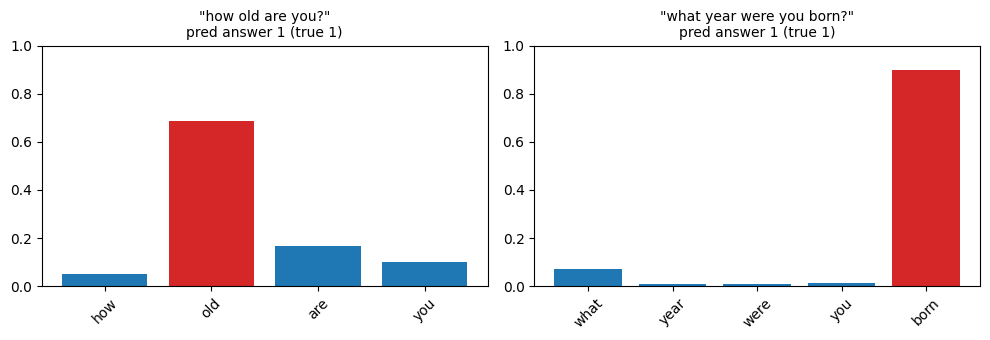

'who created you?'                            -> highest attention: 'created' (0.47)
'which company made you?'                     -> highest attention: 'company' (0.69)


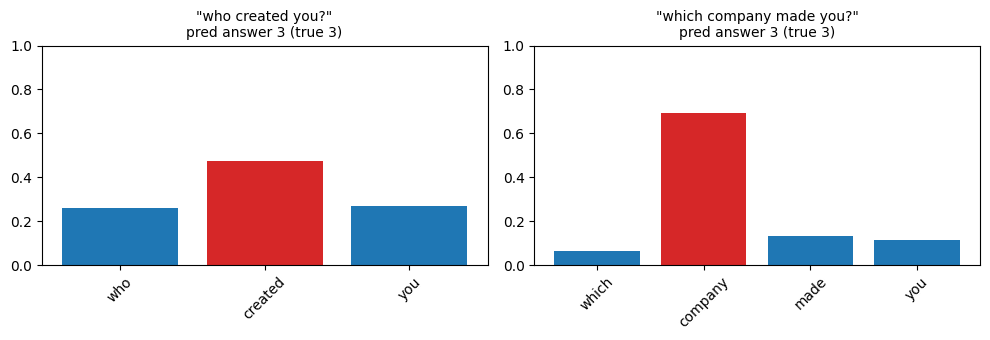

In [9]:
# Pair A: both ask about age ("how old" vs "what year ... born")
# Pair B: both ask who made the bot
pairs = [("how old are you?", "what year were you born?"),
         ("who created you?", "which company made you?")]
for a, b in pairs:
    plot_attention([idx(a), idx(b)])

### Answer — Task 2
| Pair (same meaning) | Top word of Q1 | Top word of Q2 |
|---|---|---|
| "how old are you?" / "what year were you born?" | **old** (0.69) | **born** (0.90) |
| "who created you?" / "which company made you?" | **created** (0.47) | **company** (0.69) |

**Same or different words?** Different words — but in both pairs the attended word is the *content word that carries the topic* (`old` / `born` → age, `created` / `company` → creator), and both questions are classified to the same answer (age group, creator group). The filler words (`are`, `you`, `what`, `were`) get little weight.

**What it suggests:** attention does not look for specific literal words; it learns to focus on the words that are most informative for the task. Because the embeddings/RNN map different words with similar meaning (`old`, `born`) to useful representations for the same answer, the model can pick *different* words yet reach the *same* decision. Attention is therefore a learned, task-driven weighting of the input, not a fixed rule about word identity.